Pulling Financial Market Data...
Fetching market data from 2016-01-01 to 2026-07-24


/var/folders/2c/yb6xjdp11v57x1r5bk7tndtm0000gn/T/ipykernel_71416/359705254.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  4 of 4 completed


Downsampling to uniform weekly frequency (Friday close)
Pulling OPEC+ Supply Data...
Merging into Master Matrix...

--- Dynamically Pulled Cleaned Weekly Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24   100.870003  91.989998       101.440002  18.700001   

            OPEC_Plus_Production  
2026-06-26             26.937156  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  
--- Summary Statistics ---
       Brent_Crude   WTI_Crude  US_Dollar_Index   VIX_Index  \
count   551.000000  551.000000       551.000000  551.000000   
mean     69.057496   64.712722        98.558348   18.317786   
std      18

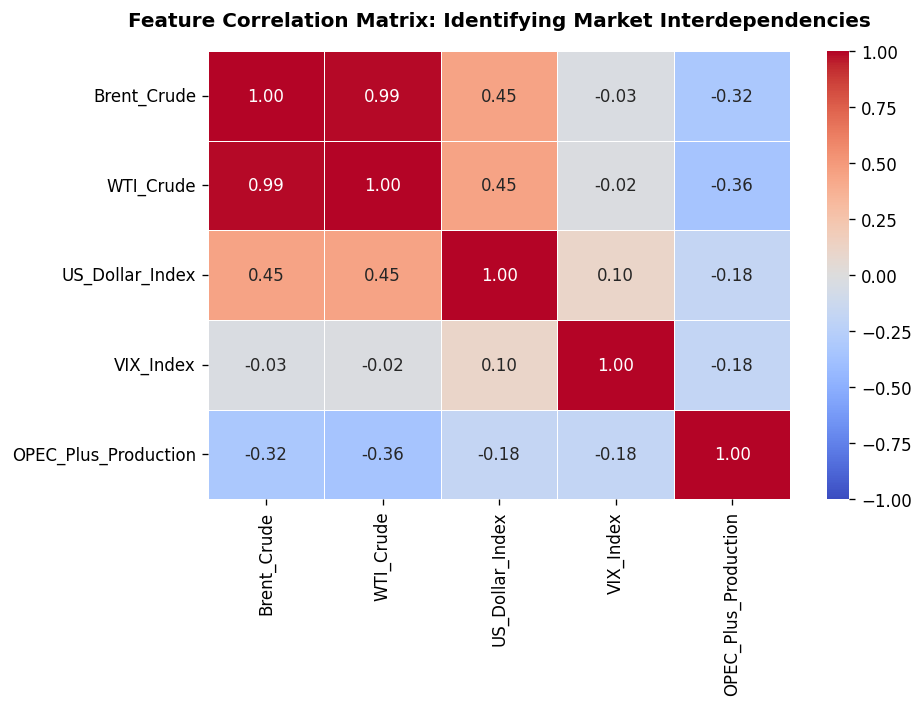

Normalization complete! New columns added to master_dataset.

--- Raw vs Normalized Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24   100.870003  91.989998       101.440002  18.700001   

            OPEC_Plus_Production  
2026-06-26             26.937156  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  

--- Smoothed Dataset (SMA, EMA and Rolling Median included) ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004

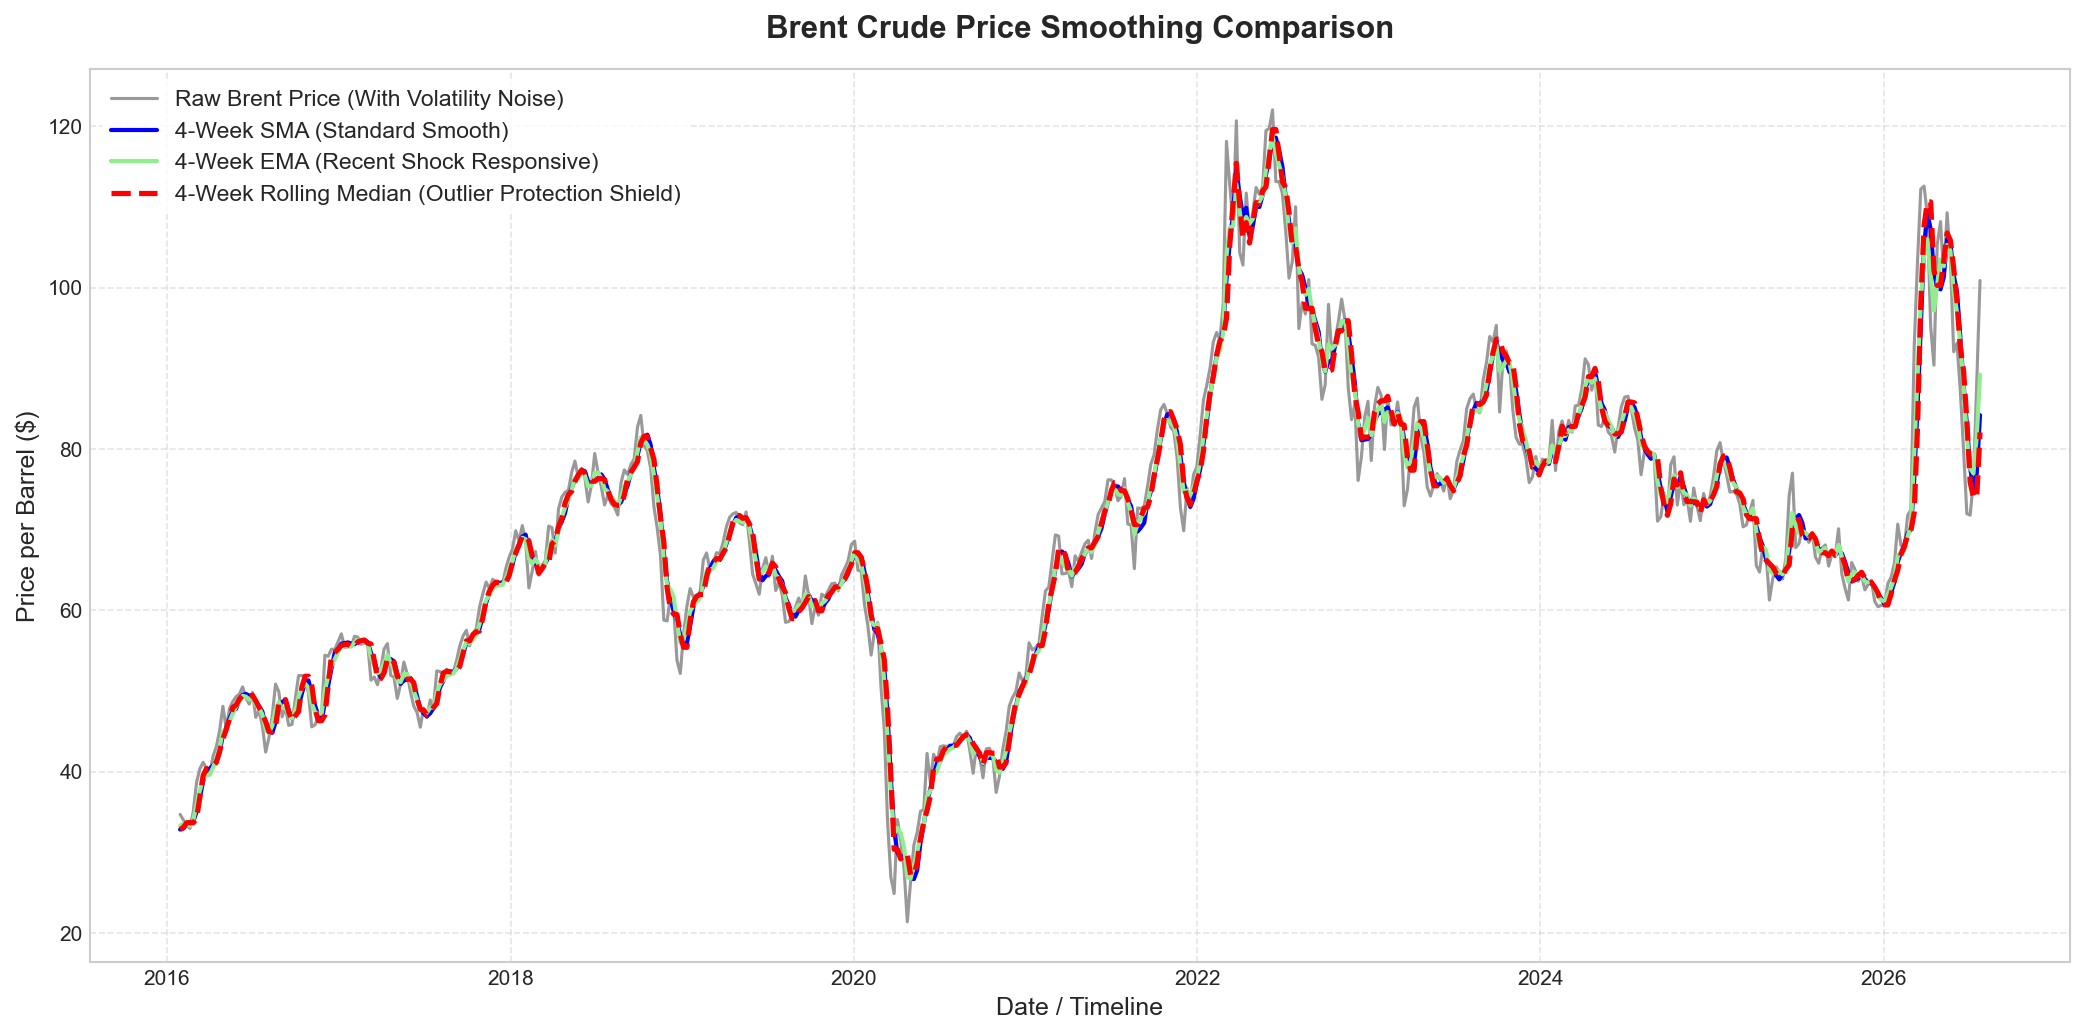

            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  OPEC_Plus_Production
2026-06-26        71.99      69.23           101.36      18.41                26.937
2026-07-03        71.80      68.69           100.86      16.15                27.517
2026-07-10        76.01      71.41           100.97      15.03                27.517
2026-07-17        88.10      82.49           100.75      18.77                27.517
2026-07-24       100.87      91.99           101.44      18.70                27.517


In [2]:
# --- RUN NOTEBOOK 1 TO GET THE DATA ---
%run data_collection_cleaning_EDA.ipynb

In [3]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

In [4]:
print("\n--- 1. FEATURE ENGINEERING (CREATING LAGGED MEMORY) ---")
# Create a copy of the master dataset for ML
ml_df = master_dataset.copy()

# Create Lags: We tell the model what the price was 1 week ago, 2 weeks ago, etc.
ml_df['Price_Lag_1'] = ml_df['Brent_Crude'].shift(1)
ml_df['Price_Lag_2'] = ml_df['Brent_Crude'].shift(2)
ml_df['Price_Lag_3'] = ml_df['Brent_Crude'].shift(3)

# Drop the first 3 rows which now have NaNs because of the shift
ml_df = ml_df.dropna()

# Define our Features (X) and Target (y)
features = ['Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'USD_Z', 'VIX_Z', 'OPEC_Z']
target = 'Brent_Crude'


--- 1. FEATURE ENGINEERING (CREATING LAGGED MEMORY) ---


In [5]:
# --- 2. TRAIN / TEST SPLIT (80/20 Chronological) ---
train_size = int(len(ml_df) * 0.8)
train_data = ml_df.iloc[:train_size]
test_data = ml_df.iloc[train_size:]

X_train, y_train = train_data[features], train_data[target]
X_test, y_test = test_data[features], test_data[target]

print(f"ML Data Ready: {len(X_train)} Train Rows, {len(X_test)} Test Rows.")

ML Data Ready: 436 Train Rows, 109 Test Rows.


In [6]:
# --- 3. TRAIN THE XGBOOST MODEL ---
# n_estimators is the number of decision trees it builds
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [7]:
# --- 4. FORECAST & EVALUATE ---
xgb_predictions = xgb_model.predict(X_test)

mae = mean_absolute_error(y_test, xgb_predictions)
rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
r2 = r2_score(y_test, xgb_predictions)

print("\n--- XGBOOST MODEL ACCURACY METRICS ---")
print(f"Mean Absolute Error (MAE):     ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R-Squared (R2 Score):          {r2:.4f}")


--- XGBOOST MODEL ACCURACY METRICS ---
Mean Absolute Error (MAE):     $3.65
Root Mean Squared Error (RMSE): $5.38
R-Squared (R2 Score):          0.8161


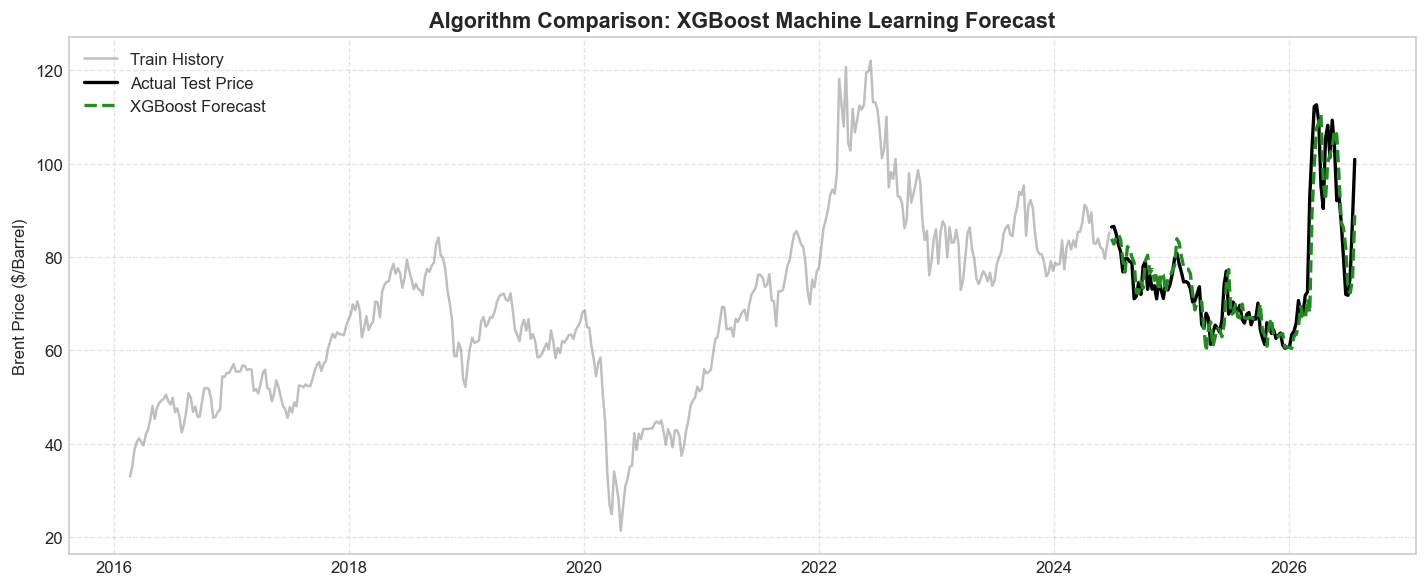

In [9]:
# --- 5. VISUALIZE COMPARISON ---
plt.figure(figsize=(12, 5), dpi=120)
plt.plot(train_data.index, y_train, label='Train History', color='grey', alpha=0.5)
plt.plot(test_data.index, y_test, label='Actual Test Price', color='black', linewidth=2)
plt.plot(test_data.index, xgb_predictions, label='XGBoost Forecast', color='forestgreen', linestyle='--', linewidth=2)

plt.title('Algorithm Comparison: XGBoost Machine Learning Forecast', fontsize=13, fontweight='bold')
plt.ylabel('Brent Price ($/Barrel)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()